In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn import linear_model
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from math import sqrt
df = pd.read_excel("../../clean_coast_data.xlsx")

In [2]:
# using get_dummies on education column
encoded = pd.get_dummies(df.Area)
# Concatenate the dummies to original dataframe
merged_data = pd.concat([df, encoded], axis=1)
# dropping the original column which was not encoded
merged_data.drop(columns='Area', inplace=True)

In [3]:
merged_data = merged_data[merged_data['Eilat'] != 1]

In [4]:
merged_data['Date test num'] = merged_data['Date test'].view(np.int64)
without_nulls = merged_data.dropna()

In [6]:
import sys
sys.path.append('../')
import utils
# print(without_nulls.columns)
without_nulls = utils.remove_if_exist(without_nulls)

without_nulls = utils.remove_high_corr(without_nulls)
print(without_nulls.columns)

Index(['city rank', 'summer_vaction', 'river', 'military', 'nature',
       'Date test', 'test_result_num', 'hifa_port_dis', 'sore_lengh',
       'temperture ', 'rain', 'rain-1day', 'rain-3days', 'Center',
       'Date test num', 'test_result'],
      dtype='object')


Quick & Dirty

In [7]:

y = without_nulls[['test_result','Date test']]
X = without_nulls.drop(['test_result','test_result_num'],axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, test_size = 0.2)
X_train_scaler = MinMaxScaler()
X_test_scaler = MinMaxScaler()
X_train_scaled = X_train_scaler.fit_transform(X_train.drop('Date test',axis=1))
X_test_scaled = X_test_scaler.fit_transform(X_test.drop('Date test',axis=1))

mlr = linear_model.LinearRegression()
mlr.fit(X_train_scaled,y_train.test_result)

prediction = mlr.predict(X_train_scaled)
resTrain =  pd.DataFrame(
    data={
        'Prediction':prediction, 
        'Actual': y_train.test_result.values    },
        index=y_train['Date test']
)
prediction = mlr.predict(X_test_scaled)
resTest = pd.DataFrame(
    data={
        'Prediction':prediction,
        'Actual': y_test.test_result.values    },
        index=y_test['Date test']
)

print('rmse train',sqrt(mean_squared_error(resTrain.Prediction, resTrain.Actual)))
print('std train',np.std(resTrain.Actual))
print('Sample')
print(resTrain.sample(10))
print()

print('rmse test',sqrt(mean_squared_error(resTest.Prediction, resTest.Actual)))
print('std test',np.std(resTest.Actual))
print('Sample')
print(resTest.sample(10))
print()

rmse train 0.9612835443460661
std train 0.9880291453199596
Sample
            Prediction  Actual
Date test                     
2005-10-02    3.406585       1
2011-09-04    4.001039       5
2018-04-30    4.106564       5
2016-11-22    3.677376       3
2020-09-30    3.573773       3
2019-10-30    4.102658       4
2017-08-15    4.029606       4
2014-07-27    3.802697       4
2021-01-31    4.001627       4
2016-03-29    3.824370       3

rmse test 0.9615203216954903
std test 0.9869020983796637
Sample
            Prediction  Actual
Date test                     
2009-06-28    3.937046       3
2008-08-25    3.795941       4
2020-08-31    4.119989       5
2009-07-20    3.726219       3
2013-02-04    3.507874       3
2017-06-20    4.094346       3
2016-08-09    3.601918       3
2015-08-12    3.978087       4
2012-11-09    3.680627       3
2015-03-16    4.123013       3



with univariant feature selection

In [8]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
from sklearn.metrics import r2_score
stds_train = list()
rmses_train = list()
r2s_train = list()

stds_test = list()
rmses_test = list()
r2s_test = list()

X = without_nulls.drop(['Date test','test_result','test_result_num'],axis=1)
y= without_nulls[['test_result']]

f_reg_selector = SelectKBest(f_regression, k=9)
f_reg_selector.fit(X, y)
f_reg_support = f_reg_selector.get_support()
f_reg_feature = X.loc[:,f_reg_support].columns.to_list()

uniX = X.loc[:,f_reg_support]
# 
for i in range(100):
    X_train, X_test, y_train, y_test = train_test_split(uniX, y, shuffle=True, test_size = 0.2)
    X_train_scaler = MinMaxScaler()
    X_test_scaler = MinMaxScaler()
    X_train_scaled = X_train_scaler.fit_transform(X_train)
    X_test_scaled = X_test_scaler.fit_transform(X_test)

    mlr = linear_model.LinearRegression()
    mlr.fit(X_train_scaled,y_train.test_result)

    prediction = mlr.predict(X_train_scaled)
    resTrain =  pd.DataFrame(
        data={
            'Prediction':prediction, 
            'Actual': y_train.test_result.values    },
    )
    prediction = mlr.predict(X_test_scaled)
    resTest = pd.DataFrame(
        data={
            'Prediction':prediction,
            'Actual': y_test.test_result.values    },
    )
    train_rmse = sqrt(mean_squared_error(resTrain.Prediction, resTrain.Actual))
    train_std = np.std(resTrain.Actual)
    train_r2 = r2_score(resTrain.Actual, resTrain.Prediction)
    test_rmse = sqrt(mean_squared_error(resTest.Prediction, resTest.Actual))
    test_std = np.std(resTest.Actual)
    test_r2 = r2_score(resTest.Actual, resTest.Prediction)
    stds_train.append(train_std)
    rmses_train.append(train_rmse)
    r2s_train.append(train_r2)
    stds_test.append(test_std)
    rmses_test.append(test_rmse)
    r2s_test.append(test_r2)

print("train std: ",np.mean(stds_train))
print("train rmse: ",np.mean(rmses_train))
print("train r2: ",np.mean(r2s_train))
print()
print("test std: ",np.mean(stds_test))
print("test rmse: ",np.mean(rmses_test))
print("test r2: ",np.mean(r2s_test))

c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\utils\validation.py:72: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  return f(**kwargs)
c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:302: RuntimeWarning: invalid value encountered in true_divide
  corr /= X_norms


train std:  0.9876521360514302
train rmse:  0.9615228986423675
train r2:  0.05221098139430248

test std:  0.988269758329151
test rmse:  0.9624053118173858
test r2:  0.051642943981325864


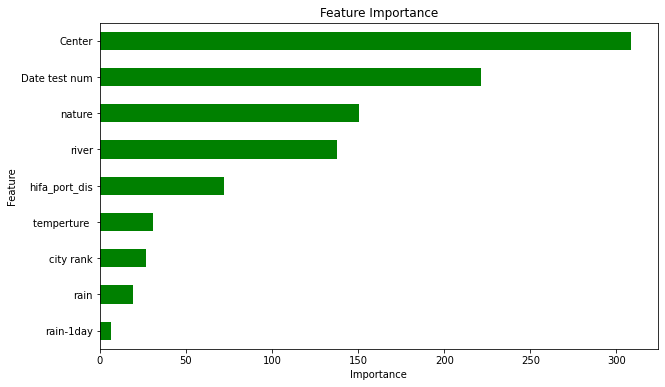

In [9]:
scores = pd.Series(f_reg_selector.scores_.tolist()) 
p_values = pd.Series(f_reg_selector.pvalues_.tolist()) 
selected_df = pd.DataFrame({'univariate_score':scores, 'p_values':p_values})
selected_df.set_index(X.columns, inplace=True, drop=True)
univariate = selected_df.sort_values(by='univariate_score', ascending=False)

univariate = univariate.loc[univariate.index.isin(f_reg_feature)]
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))
global_importances = pd.Series(univariate['univariate_score'], index=list(univariate.index))
global_importances.sort_values(ascending=True, inplace=True)
global_importances.plot.barh(color='green')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.show()

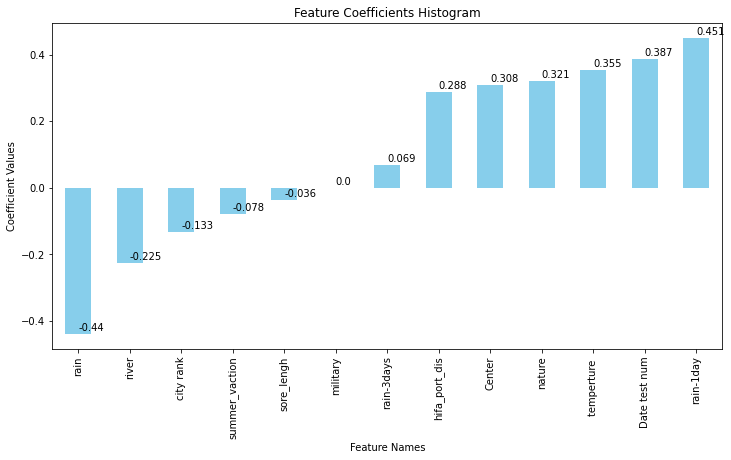

In [10]:
#find coeff based on all examples

X_scaler = MinMaxScaler()
X_scaled = X_scaler.fit_transform(X)

mlr = linear_model.LinearRegression()
mlr.fit(X_scaled,y.test_result)

coef = sorted( list(zip(np.round(mlr.coef_,5).T,X.columns)))
d = {}
for tup in coef:
    d[tup[-1]] = tup[0]
coefDF = pd.DataFrame.from_dict(d,orient='index')
coefDF.columns = ['coeff']

import pandas as pd
import matplotlib.pyplot as plt

# Assuming df is your DataFrame with a 'coeff' column

# Plotting a histogram
coefDF.columns = ['coeff']
coefDF['coeff'].plot(kind='bar', figsize=(12, 6), color='skyblue')
plt.xlabel('Feature Names')
plt.ylabel('Coefficient Values')
plt.title('Feature Coefficients Histogram')

# Displaying the row names (index) on top of each bar
for i, value in enumerate(coefDF['coeff']):
    plt.text(i, value + 0.01, str(round(value,3)))

plt.show()
